# Task 2 Nonlinear models

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import missingno as msno
import seaborn as sns

## Auxiliary functions

In [2]:
def cMSE(y, y_hat, c):
    err = y-y_hat
    err = (1-c)*err**2 + c*np.maximum(0,err)**2
    return np.sum(err)/err.shape[0]
    
def plot_y_yhat(y_test, y_pred, plot_title="plot"):
    # Only one target variable: SurvivalTime
    label = 'SurvivalTime'
    MAX = 500

    # Select indices for plotting
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test), MAX, replace=False)
    else:
        idx = np.arange(len(y_test))

    # Plot True vs Predicted for SurvivalTime
    plt.figure(figsize=(6, 6))
    x0 = np.min(y_test[idx])
    x1 = np.max(y_test[idx])
    plt.scatter(y_test[idx], y_pred[idx], alpha=0.7)
    plt.xlabel(f'True {label}')
    plt.ylabel(f'Predicted {label}')
    plt.plot([x0, x1], [x0, x1], color='red')
    plt.title(f'True vs Predicted {label}')
    plt.axis('square')
    plt.savefig(plot_title + '.pdf')
    plt.show()
    
def save_predictions(predictions, path):
    # Create a DataFrame with the 'id' column and the predictions
    df = pd.DataFrame({
        'id': range(len(predictions)),
        '0': predictions
    })
    
    # Save the DataFrame to a CSV file
    df.to_csv(path, index=False)

## Data preprocessing

In [3]:
df = pd.read_csv('./mlNOVA/train_data.csv')
df.drop(columns=['id'], inplace=True)
df.head()

,Age,Gender,Stage,GeneticRisk,TreatmentType,ComorbidityIndex,TreatmentResponse,SurvivalTime,Censored
0,65.0,0,2,1.0,0,0.0,0.0,4.2,0
1,68.0,1,2,0.0,1,1.0,1.0,4.7,1
2,68.0,1,3,1.0,1,0.0,1.0,3.5,1
3,81.0,1,4,1.0,1,3.0,0.0,2.3,0
4,59.0,1,2,1.0,0,NaN,0.0,NaN,0


In [4]:
# these columns have missing data ocasionally, drop them
df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time
df = df[df['SurvivalTime'].notna()]

# remove rows where 'Censored' is 1
df = df[df['Censored'] != 1]
print(f"Remaining points after removing censored rows: {df.shape[0]}")
# Display the first few rows of the cleaned dataset
df.head()

Remaining points after removing censored rows: 161


,Age,Gender,Stage,TreatmentType,SurvivalTime,Censored
0,65.0,0,2,0,4.2,0
3,81.0,1,4,1,2.3,0
5,47.0,1,4,1,2.6,0
9,68.0,1,1,0,6.4,0
11,56.0,0,2,0,4.1,0


In [5]:
X = df.drop(columns=['SurvivalTime', 'Censored'])
y = df['SurvivalTime']
c = df['Censored']

# Display the shapes of X and y to verify
print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape: {y.shape}")
print(f"Censored vector c shape: {c.shape}")

X = np.array(X)
y = np.array(y)
c = np.array(c)

Feature matrix X shape: (161, 4)
Target vector y shape: (161,)
Censored vector c shape: (161,)


In [6]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
c_train, c_test = train_test_split(c, test_size=0.2, random_state=42)

## Task 2.1 Development

### Develop functions for training Polynomial and k-Nearest Neighbors on the data prepared in Task 1.1. using the validation procedure determined in Task 1.1 and Task 1.2.

In [7]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor

# Polynomial Regression Training
def train_polynomial_regression(X, y, c, degree=2, cv=10):
    # Pipeline: PolynomialFeatures -> StandardScaler -> LinearRegression    
    polyreg = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())
    
    # Cross-validation
    y_pred_cv = cross_val_predict(polyreg, X, y, cv=cv)
    cMSE_cv = cMSE(y, y_pred_cv, c)
    print(f"Degree is {degree} | Cross-Validation Censored Mean Squared Error (cMSE): {cMSE_cv}")
    
    # Train on the entire dataset
    polyreg.fit(X, y)
    
    return polyreg, cMSE_cv


# k-Nearest Neighbors Training
def train_knn_regression(X, y, c, k=5, cv=10):
    # k-NN Regressor
    knn_reg=make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    
    # Cross-validation
    y_pred_cv = cross_val_predict(knn_reg, X, y, cv=cv)
    cMSE_cv = cMSE(y, y_pred_cv, c)
    print(f"K is {k} | Cross-Validation Censored Mean Squared Error (cMSE): {cMSE_cv}")
    
    # Train on the entire dataset
    knn_reg.fit(X, y)
    
    return knn_reg, cMSE_cv


### Select the model hyperparamenters, like the polynomial degree and the $k$ using cross validation for model selection.

#### Visualize polynomial degree performance

Degree is 1 | Cross-Validation Censored Mean Squared Error (cMSE): 4.390046220294185
Degree is 2 | Cross-Validation Censored Mean Squared Error (cMSE): 4.517158263706202
Degree is 3 | Cross-Validation Censored Mean Squared Error (cMSE): 5.942301864754408
Degree is 4 | Cross-Validation Censored Mean Squared Error (cMSE): 21.805180693055547
Degree is 5 | Cross-Validation Censored Mean Squared Error (cMSE): 464.59359470091925


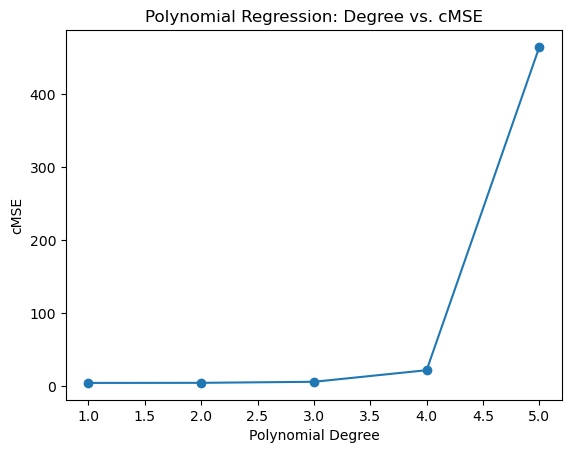

In [8]:
degrees = [1, 2, 3, 4, 5]
poly_scores = []

for d in degrees:
    _, score = train_polynomial_regression(X_train, y_train, c_train, degree=d, cv=10)
    poly_scores.append(score)

plt.plot(degrees, poly_scores, marker='o')
plt.xlabel("Polynomial Degree")
plt.ylabel("cMSE")
plt.title("Polynomial Regression: Degree vs. cMSE")
plt.show()

#### Visualize k performance

K is 3 | Cross-Validation Censored Mean Squared Error (cMSE): 5.374348958333333
K is 5 | Cross-Validation Censored Mean Squared Error (cMSE): 5.11033125
K is 7 | Cross-Validation Censored Mean Squared Error (cMSE): 4.565420918367347
K is 9 | Cross-Validation Censored Mean Squared Error (cMSE): 4.310432098765432
K is 11 | Cross-Validation Censored Mean Squared Error (cMSE): 4.18060756714876
K is 13 | Cross-Validation Censored Mean Squared Error (cMSE): 4.063429641272189
K is 15 | Cross-Validation Censored Mean Squared Error (cMSE): 4.188443055555555
K is 17 | Cross-Validation Censored Mean Squared Error (cMSE): 4.303502649221453
K is 19 | Cross-Validation Censored Mean Squared Error (cMSE): 4.273320420706371
K is 21 | Cross-Validation Censored Mean Squared Error (cMSE): 4.206501027494331
K is 23 | Cross-Validation Censored Mean Squared Error (cMSE): 4.270166735586011
K is 25 | Cross-Validation Censored Mean Squared Error (cMSE): 4.3099282500000005


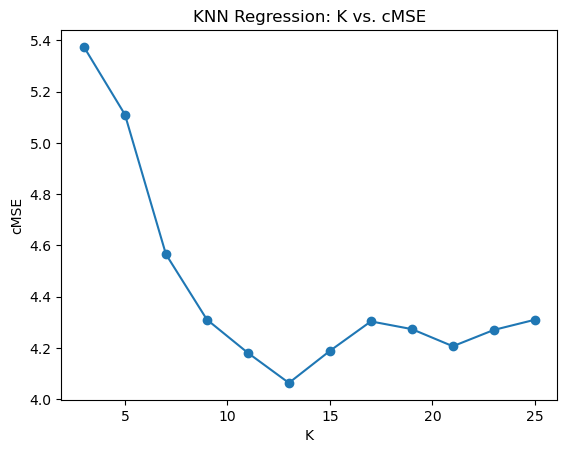

In [9]:
k_values = [3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25]
knn_scores = []

for k in k_values:
    _, score = train_knn_regression(X_train, y_train, c_train, k=k, cv=10)
    knn_scores.append(score)

plt.plot(k_values, knn_scores, marker='o')
plt.xlabel("K")
plt.ylabel("cMSE")
plt.title("KNN Regression: K vs. cMSE")
plt.show()

## Task 2.2 Evaluation

### Evaluate the models developed in Task 2.1 against the baseline. Always back up your analysis with evidence, e.g., by showing a table with the different models and max, min, mean error, and standard deviation of the error.

#### KNN model

Best k is 13

In [12]:
knn_reg, score = train_knn_regression(X_train, y_train, c_train, k=13, cv=10)

y_pred_test = knn_reg.predict(X_test)
cMSE_test = cMSE(y_test, y_pred_test, c_test)
print(f"Test Set Censored Mean Squared Error (cMSE): {cMSE_test}")

K is 13 | Cross-Validation Censored Mean Squared Error (cMSE): 4.063429641272189
Test Set Censored Mean Squared Error (cMSE): 4.589878070647302


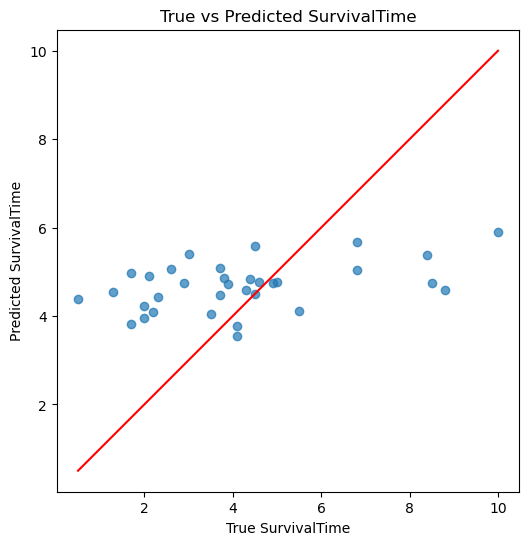

In [32]:
plot_y_yhat(y_test, y_pred_test, plot_title="y_yhat_plot")

Model evaluation

In [ ]:
def evaluate_model(y_true, y_pred):
    error = y_true - y_pred
    metrics = {
        'Max Error': np.max(np.abs(error)),
        'Min Error': np.min(np.abs(error)),
        'Mean Error': np.mean(np.abs(error)),
        'Std of Error': np.std(error)
    }
    return metrics

In [39]:
# Baseline: Mean Prediction
linear_reg, score = train_polynomial_regression(X_train, y_train, c_train, degree=1, cv=10)
y_pred_linear = linear_reg.predict(X_test)
baseline_metrics = evaluate_model(y_test, y_pred_linear)
print("Baseline Model Metrics:", baseline_metrics)

# Polynomial Regression
poly_reg, score = train_polynomial_regression(X_train, y_train, c_train, degree=2, cv=10)
y_pred_poly = poly_reg.predict(X_test)  # Use the final trained Polynomial Regression model
poly_metrics = evaluate_model(y_test, y_pred_poly)
print("Polynomial Regression Metrics:", poly_metrics)

# k-NN
y_pred_knn = knn_reg.predict(X_test)  # Use the final trained k-NN model
knn_metrics = evaluate_model(y_test, y_pred_knn)
print("k-NN Metrics:", knn_metrics)

Degree is 1 | Cross-Validation Censored Mean Squared Error (cMSE): 4.390046220294185
Baseline Model Metrics: {'Max Error': 4.934076718710074, 'Min Error': 0.007779729729391782, 'Mean Error': 1.678044236209491, 'Std of Error': 2.0524208408201963}
Degree is 2 | Cross-Validation Censored Mean Squared Error (cMSE): 4.517158263706202
Polynomial Regression Metrics: {'Max Error': 4.718994140625, 'Min Error': 0.055810546874999645, 'Mean Error': 1.7679791074810607, 'Std of Error': 2.120271923366158}
k-NN Metrics: {'Max Error': 4.207692307692309, 'Min Error': 0.007692307692307665, 'Mean Error': 1.7410256410256408, 'Std of Error': 2.0856723824590393}


In [40]:
# Combine metrics into a DataFrame
comparison_table = pd.DataFrame({
    'Baseline': baseline_metrics,
    'Polynomial Regression': poly_metrics,
    'k-NN': knn_metrics
}).T

print(comparison_table)


                       Max Error  Min Error  Mean Error  Std of Error
Baseline                4.934077   0.007780    1.678044      2.052421
Polynomial Regression   4.718994   0.055811    1.767979      2.120272
k-NN                    4.207692   0.007692    1.741026      2.085672


Load Kaggle dataset and process it

In [33]:
X_kaggle_df = pd.read_csv('./mlNOVA/test_data.csv')
X_kaggle_df.drop(columns=['id'], inplace=True)
# these columns have missing data ocasionally
X_kaggle_df.drop(columns=['GeneticRisk', 'ComorbidityIndex', 'TreatmentResponse'], inplace=True)
# drop rows with missing Survival Time or any other missing value
X_kaggle_df = X_kaggle_df.dropna()
# Display the first few rows of the cleaned dataset
X_kaggle_df.head()

,Age,Gender,Stage,TreatmentType
0,71.0,1,4,1
1,57.0,1,4,0
2,66.0,0,2,0
3,73.0,0,3,1
4,53.0,1,4,0


Save prediction

In [34]:
y_knn_pred = knn_reg.predict(X_kaggle_df)
save_predictions(y_knn_pred, './submissions/Nonlinear-submission-02.csv')

c:\Users\rasvi\anaconda3\envs\ml\Lib\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(
